# Project 47 — Data-Driven Cloth for Interactive Applications (CS229-style study)

**Important — synthetic data.** This notebook does **not** use real cloth simulations. Poses and
"cloth deformations" are generated by a synthetic function (below). Consequently:

* the numbers here are **not** a replication of the paper's results and must not be compared to them;
* any conclusion (e.g. which PCA size is best, how much better an MLP is than linear regression) is a
  property of *this synthetic generator*, not of real cloth;
* what this notebook *does* test is the **pipeline**: PCA output layer, train/val/test discipline,
  early stopping, reproducibility and evaluation.

Fixed design (kept from the original): 56-D input (14 unit quaternions), 6,510-D output
(2,170 vertices x 3), 10,000 -> 9,813 samples, 6000/2000/1813 split, PCA k in {64, 128, 256},
linear-regression baseline, MLP 56 -> 128 -> 256 -> output.

**Protocol.** Train set: fit PCA, fit/optimise models. Validation set: early stopping + choosing the
best configuration. Test set: only reported, never used to make any decision.

In [23]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # needed for deterministic CUDA matmuls

import copy, random, time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

# ----------------------------- configuration -----------------------------
DATA_SEED   = 42                 # synthetic data generation + split
MODEL_SEEDS = (0, 1, 2)          # independent training runs per configuration
N_SAMPLES, N_JOINTS, N_VERTS = 10_000, 14, 2170
IN_DIM, OUT_DIM = N_JOINTS * 4, N_VERTS * 3        # 56, 6510
N_KEEP, N_TRAIN, N_VAL, N_TEST = 9813, 6000, 2000, 1813
OUTLIER_THRESH = 0.0350          # mean squared vertex distance threshold (from the original notebook)
NOISE_STD      = 0.0035
PCA_KS         = (64, 128, 256)
BATCH_SIZE, LR, MAX_EPOCHS, PATIENCE = 32, 2e-4, 150, 15

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(DATA_SEED)
print(f"device={device} | torch={torch.__version__}")

device=cuda | torch=2.6.0+cu124


## 1. Synthetic dataset (unchanged generator) and outlier removal

The generator is the original one. Honest notes:

* The linear part of the signal is `X @ W_lin @ V_mesh`, which is linear in the 56 inputs, so its rank is at most 56.
  The "non-linear" terms (`0.025*sin(3z)`, `0.015*cos(5z)`) are small relative to z (std about 0.056), i.e. the
  data is **close to linearly predictable**. The original comment that linear models "fail to fit" it is not borne out
  (see results): this dataset cannot demonstrate a large benefit of a non-linear model.
* The original filter (`mean sq. distance <= 0.035`) removed **nothing** (max value is about 4e-4), and the data were then
  silently truncated with `[:9813]`. Here 187 "failed simulation" samples (deformation scaled up 20-40x) are
  explicitly injected so the 10,000 -> 9,813 filtering step is real, and we assert that it removes exactly those.

In [24]:
rng = np.random.default_rng(DATA_SEED)

# 1. 14 unit quaternions per sample -> 56-D pose
raw_quats = rng.standard_normal((N_SAMPLES, N_JOINTS, 4))
quats = raw_quats / np.linalg.norm(raw_quats, axis=-1, keepdims=True)
X_all = quats.reshape(N_SAMPLES, IN_DIM)

# 2. Synthetic non-linear deformation manifold (same functional form as the original)
W_lin  = rng.standard_normal((IN_DIM, 128)) * 0.015
V_mesh = rng.standard_normal((128, OUT_DIM)) * 0.012
Z_linear = X_all @ W_lin
Z_folds  = 0.025 * np.sin(3.0 * Z_linear) + 0.015 * np.cos(5.0 * Z_linear[:, ::-1])
Z_total  = Z_linear + Z_folds
noise = rng.standard_normal((N_SAMPLES, OUT_DIM), dtype=np.float32) * NOISE_STD   # i.i.d., ~1.2e-5 irreducible MSE
Y_all = (Z_total @ V_mesh + noise).astype(np.float32)
del noise

# 3. Inject 187 failed-simulation outliers, then apply the threshold filter
N_OUT = N_SAMPLES - N_KEEP
out_idx = rng.choice(N_SAMPLES, N_OUT, replace=False)
Y_all[out_idx] *= rng.uniform(20.0, 40.0, size=(N_OUT, 1)).astype(np.float32)

msd = np.mean((Y_all.reshape(N_SAMPLES, N_VERTS, 3) ** 2).sum(-1), axis=1)
valid = msd <= OUTLIER_THRESH
is_injected = np.zeros(N_SAMPLES, bool); is_injected[out_idx] = True
assert valid.sum() == N_KEEP, valid.sum()
assert np.array_equal(~valid, is_injected), "filter must remove exactly the injected outliers"
print(f"clean max msd = {msd[valid].max():.2e} | outlier min msd = {msd[~valid].min():.2e} | threshold = {OUTLIER_THRESH}")

X_clean, Y_clean = X_all[valid], Y_all[valid]

# 4. Random (seeded) 6000 / 2000 / 1813 split
perm = rng.permutation(N_KEEP)
tr_i, va_i, te_i = perm[:N_TRAIN], perm[N_TRAIN:N_TRAIN + N_VAL], perm[N_TRAIN + N_VAL:]
assert len(te_i) == N_TEST and not (set(tr_i) & set(va_i) | set(tr_i) & set(te_i) | set(va_i) & set(te_i))
X_train, Y_train = X_clean[tr_i], Y_clean[tr_i]
X_val,   Y_val   = X_clean[va_i], Y_clean[va_i]
X_test,  Y_test  = X_clean[te_i], Y_clean[te_i]
print(f"Train {len(X_train)} | Val {len(X_val)} | Test {len(X_test)} | X dim {X_train.shape[1]} | Y dim {Y_train.shape[1]}")

clean max msd = 3.56e-04 | outlier min msd = 9.42e-02 | threshold = 0.035
Train 6000 | Val 2000 | Test 1813 | X dim 56 | Y dim 6510


## 2. PCA of vertex offsets

PCA is fit on the **training** targets only (asserted). Components are nested, so one 256-component fit
is truncated to 64 / 128 / 256. The *reconstruction floor* is the error of projecting the true target onto the
first k components: no model that predicts k coefficients can beat it. The noise floor is the
i.i.d. noise variance `NOISE_STD**2`, the error even a perfect noise-free predictor would incur.
Cumulative variance saturates near 85-87% because about 15% of total variance is isotropic noise spread over 6,510 dimensions,
so the 90% / 99% marks are never reached (the original code silently reported 1 component in that case).

cumulative variance @64/128/256 = 0.8473 / 0.8533 / 0.8643
components for 90% variance: None | for 99%: None   (None = not reached within 256)

noise floor (i.i.d. noise variance) = 1.225e-05
PCA-64  reconstruction floor  val = 1.226e-05   test = 1.225e-05
PCA-128 reconstruction floor  val = 1.213e-05   test = 1.213e-05
PCA-256 reconstruction floor  val = 1.189e-05   test = 1.189e-05


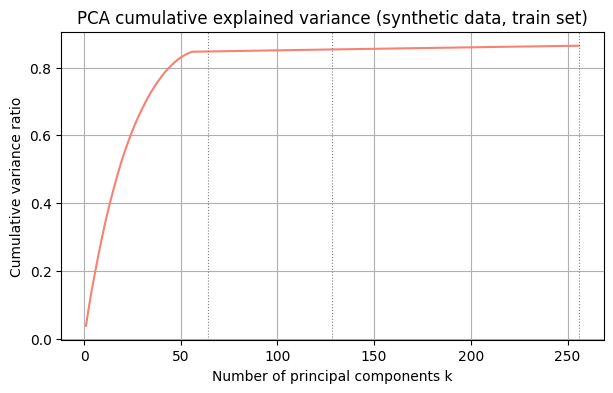

In [25]:
pca = PCA(n_components=max(PCA_KS), svd_solver="full", random_state=DATA_SEED)
pca.fit(Y_train.astype(np.float64))
assert pca.n_samples_ == N_TRAIN          # fitted on training targets only (no val/test leakage)

cum_var = np.cumsum(pca.explained_variance_ratio_)
def first_reaching(frac):
    hit = np.flatnonzero(cum_var >= frac)
    return int(hit[0]) + 1 if hit.size else None      # None if never reached (original code returned 1 here)
k90, k99 = first_reaching(0.90), first_reaching(0.99)

def recon_mse(Y, k):
    V, mu = pca.components_[:k], pca.mean_
    Yc = Y.astype(np.float64) - mu
    return float(np.mean((Yc @ V.T @ V - Yc) ** 2))

noise_floor = NOISE_STD ** 2
print(f"cumulative variance @64/128/256 = {cum_var[63]:.4f} / {cum_var[127]:.4f} / {cum_var[255]:.4f}")
print(f"components for 90% variance: {k90} | for 99%: {k99}   (None = not reached within {max(PCA_KS)})")
print(f"\nnoise floor (i.i.d. noise variance) = {noise_floor:.3e}")
recon_floor = {}
for k in PCA_KS:
    recon_floor[k] = (recon_mse(Y_val, k), recon_mse(Y_test, k))
    print(f"PCA-{k:<3} reconstruction floor  val = {recon_floor[k][0]:.3e}   test = {recon_floor[k][1]:.3e}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(cum_var) + 1), cum_var, color="salmon")
for k in PCA_KS: ax.axvline(k, color="gray", ls=":", lw=0.8)
if k90: ax.axvline(k90, color="gray", ls="--", label=f"90% variance ({k90} comps)")
if k99: ax.axvline(k99, color="black", ls="--", label=f"99% variance ({k99} comps)")
ax.set_title("PCA cumulative explained variance (synthetic data, train set)")
ax.set_xlabel("Number of principal components k"); ax.set_ylabel("Cumulative variance ratio")
ax.grid(True); ax.legend() if (k90 or k99) else None
plt.show()

## 3. Models, training with validation-based early stopping

* `PCADecoder` stores `components` / `mean` as **buffers** (not parameters): they move with the model and are
  saved in checkpoints but are never optimised or passed to the optimiser.
* The loss is MSE in the *full vertex space* (through the fixed decoder), as in the original design.
* Each epoch records train and validation MSE. The checkpoint with the lowest **validation** MSE is restored
  (early stopping, patience `PATIENCE`). The test set is not touched during training.
* Each run seeds weight init and the shuffling order explicitly.

In [26]:
class PCADecoder(nn.Module):
    # Fixed linear decoder: y = c @ V_k + mean
    def __init__(self, components, mean):
        super().__init__()
        self.register_buffer("components", torch.as_tensor(components, dtype=torch.float32))
        self.register_buffer("mean", torch.as_tensor(mean, dtype=torch.float32))
    def forward(self, c):
        return c @ self.components + self.mean

class ClothMLP(nn.Module):
    # MLP 56 -> 128 -> 256 -> (6510 vertex offsets | k PCA coefficients -> fixed decoder)
    def __init__(self, k=None):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(IN_DIM, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, OUT_DIM if k is None else k),
        )
        self.decoder = None if k is None else PCADecoder(pca.components_[:k], pca.mean_)
    def forward(self, x):
        out = self.net(x)
        return out if self.decoder is None else self.decoder(out)

T = lambda a: torch.as_tensor(a, dtype=torch.float32, device=device)
Xtr_t, Ytr_t, Xva_t, Yva_t, Xte_t, Yte_t = map(T, (X_train, Y_train, X_val, Y_val, X_test, Y_test))

@torch.no_grad()
def predict(model, X, bs=1024):
    model.eval()
    return torch.cat([model(X[i:i + bs]) for i in range(0, len(X), bs)])

def mse(pred, Y):
    return ((pred - Y) ** 2).mean().item()

def vertex_err(pred, Y):
    # mean Euclidean error per vertex (same units as the data)
    return (pred - Y).reshape(-1, N_VERTS, 3).norm(dim=-1).mean().item()

def train_model(model, seed, max_epochs=MAX_EPOCHS, patience=PATIENCE, lr=LR, bs=BATCH_SIZE):
    model.to(device)
    g = torch.Generator().manual_seed(seed)                    # controls shuffling
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    n, best_val, best_state, best_ep, bad, hist = len(Xtr_t), float("inf"), None, 0, 0, []
    for ep in range(1, max_epochs + 1):
        model.train()
        order = torch.randperm(n, generator=g).to(device)
        tot = 0.0
        for i in range(0, n, bs):
            idx = order[i:i + bs]
            opt.zero_grad(set_to_none=True)
            loss = ((model(Xtr_t[idx]) - Ytr_t[idx]) ** 2).mean()
            loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        val = mse(predict(model, Xva_t), Yva_t)
        hist.append((tot / n, val))
        if val < best_val:
            best_val, best_ep, bad = val, ep, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)                          # restore best-validation checkpoint
    return hist, best_ep

## 4. Baselines

Mean-prediction (sanity floor) and the linear-regression baseline, fitted on the training set and
evaluated on validation and test.

In [27]:
rows = []   # (name, hidden, output, {split: mse})
mean_pred = Y_train.mean(0, keepdims=True)
rows.append(("Predict train mean", "-", "Vertex offsets (6510)",
             {s: float(np.mean((mean_pred - Y) ** 2)) for s, Y in (("train", Y_train), ("val", Y_val), ("test", Y_test))}))

lin = LinearRegression().fit(X_train, Y_train)
lin_mse = {s: float(np.mean((lin.predict(X) - Y) ** 2)) for s, X, Y in
           (("train", X_train, Y_train), ("val", X_val, Y_val), ("test", X_test, Y_test))}
rows.append(("Linear regression", "-", "Vertex offsets (6510)", lin_mse))
print({k: f"{v:.3e}" for k, v in lin_mse.items()})

{'train': '1.214e-05', 'val': '1.238e-05', 'test': '1.238e-05'}


## 5. MLP ablation (3 seeds per configuration)

In [28]:
configs = [("MLP 128-256", "Vertex offsets (6510)", None)] + \
          [("MLP 128-256", f"{k} PCA coeffs ({k})", k) for k in PCA_KS]

runs = {}       # label -> list of dicts, one per seed
models = {}     # (label, seed) -> trained model
t0 = time.time()
for name, out_lbl, k in configs:
    runs[out_lbl] = []
    for seed in MODEL_SEEDS:
        set_seed(seed)
        model = ClothMLP(k)
        hist, best_ep = train_model(model, seed)
        p_tr, p_va, p_te = (predict(model, X) for X in (Xtr_t, Xva_t, Xte_t))
        runs[out_lbl].append(dict(
            seed=seed, hist=hist, best_epoch=best_ep, epochs_run=len(hist),
            train=mse(p_tr, Ytr_t), val=mse(p_va, Yva_t), test=mse(p_te, Yte_t),
            test_vertex_err=vertex_err(p_te, Yte_t)))
        models[(out_lbl, seed)] = model
        r = runs[out_lbl][-1]
        print(f"{out_lbl:<26} seed {seed} | best ep {best_ep:>3}/{len(hist):<3} | "
              f"train {r['train']:.3e} val {r['val']:.3e} test {r['test']:.3e}  ({time.time()-t0:.0f}s)")

Vertex offsets (6510)      seed 0 | best ep 111/126 | train 3.974e-05 val 4.007e-05 test 4.008e-05  (90s)
Vertex offsets (6510)      seed 1 | best ep 127/142 | train 3.422e-05 val 3.472e-05 test 3.479e-05  (190s)
Vertex offsets (6510)      seed 2 | best ep 123/138 | train 4.129e-05 val 4.160e-05 test 4.155e-05  (287s)
64 PCA coeffs (64)         seed 0 | best ep  91/106 | train 1.217e-05 val 1.244e-05 test 1.244e-05  (333s)
64 PCA coeffs (64)         seed 1 | best ep  80/95  | train 1.218e-05 val 1.245e-05 test 1.244e-05  (375s)
64 PCA coeffs (64)         seed 2 | best ep  86/101 | train 1.217e-05 val 1.245e-05 test 1.244e-05  (419s)
128 PCA coeffs (128)       seed 0 | best ep 119/134 | train 1.220e-05 val 1.247e-05 test 1.247e-05  (476s)
128 PCA coeffs (128)       seed 1 | best ep  85/100 | train 1.220e-05 val 1.248e-05 test 1.247e-05  (518s)
128 PCA coeffs (128)       seed 2 | best ep  88/103 | train 1.221e-05 val 1.248e-05 test 1.248e-05  (561s)
256 PCA coeffs (256)       seed 0 | be

Mean +/- std over seeds (MSE per coordinate, data units^2). Selection uses VALIDATION only.

ID | Model              | Output                  | Train              | Val                | Test               
-----------------------------------------------------------------------------------------------------------------
0  | Predict train mean | Vertex offsets (6510)   | 7.842e-05          | 7.796e-05          | 7.807e-05          
1  | Linear regression  | Vertex offsets (6510)   | 1.214e-05          | 1.238e-05          | 1.238e-05          
2  | MLP 128-256        | Vertex offsets (6510)   | 3.842e-05+/-3.0e-06| 3.880e-05+/-2.9e-06| 3.881e-05+/-2.9e-06
3  | MLP 128-256        | 64 PCA coeffs (64)      | 1.218e-05+/-2.7e-09| 1.244e-05+/-2.1e-09| 1.244e-05+/-2.1e-09
4  | MLP 128-256        | 128 PCA coeffs (128)    | 1.220e-05+/-4.3e-09| 1.248e-05+/-3.5e-09| 1.247e-05+/-2.5e-09
5  | MLP 128-256        | 256 PCA coeffs (256)    | 1.225e-05+/-3.4e-09| 1.253e-05+/-4.2e-09| 1.253e-05+/-3.0

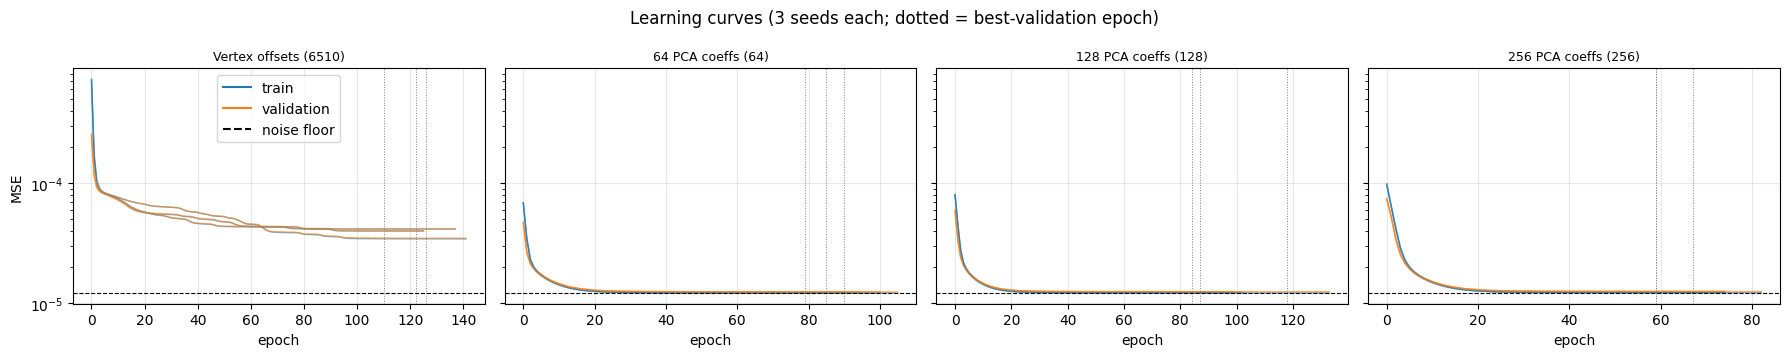

In [29]:
def ms(vals): return np.mean(vals), np.std(vals)

print("Mean +/- std over seeds (MSE per coordinate, data units^2). Selection uses VALIDATION only.\n")
hdr = f"{'ID':<3}| {'Model':<19}| {'Output':<24}| {'Train':<19}| {'Val':<19}| {'Test':<19}"
print(hdr); print("-" * len(hdr))
for i, (nm, hid, out, d) in enumerate(rows):
    print(f"{i:<3}| {nm:<19}| {out:<24}| {d['train']:<19.3e}| {d['val']:<19.3e}| {d['test']:<19.3e}")
val_means = {}
for j, (name, out_lbl, k) in enumerate(configs, start=len(rows)):
    cell = {s: ms([r[s] for r in runs[out_lbl]]) for s in ("train", "val", "test")}
    val_means[out_lbl] = cell["val"][0]
    f = lambda s: f"{cell[s][0]:.3e}+/-{cell[s][1]:.1e}"
    print(f"{j:<3}| {name:<19}| {out_lbl:<24}| {f('train'):<19}| {f('val'):<19}| {f('test'):<19}")

selected = min(val_means, key=val_means.get)
print(f"\nSelected by lowest mean validation MSE: {selected}")
print(f"Reference floors -> noise floor {noise_floor:.3e}; PCA reconstruction floor (val): "
      + ", ".join(f"k={k}: {recon_floor[k][0]:.3e}" for k in PCA_KS))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, (_, out_lbl, _) in zip(axes, configs):
    for r in runs[out_lbl]:
        tr, va = zip(*r["hist"])
        ax.plot(tr, color="tab:blue", alpha=.6, lw=1); ax.plot(va, color="tab:orange", alpha=.6, lw=1)
        ax.axvline(r["best_epoch"] - 1, color="gray", ls=":", lw=.7)
    ax.axhline(noise_floor, color="k", ls="--", lw=.8)
    ax.set_yscale("log"); ax.set_title(out_lbl, fontsize=9); ax.set_xlabel("epoch"); ax.grid(True, alpha=.3)
axes[0].set_ylabel("MSE"); axes[0].plot([], [], color="tab:blue", label="train"); axes[0].plot([], [], color="tab:orange", label="validation")
axes[0].plot([], [], "k--", label="noise floor"); axes[0].legend()
plt.suptitle("Learning curves (3 seeds each; dotted = best-validation epoch)"); plt.tight_layout(); plt.show()

## 5b. Select the best seed and save the deployable artifacts

Within the selected configuration, the seed with the lowest **validation** MSE is used (ties -> lowest seed). The test set plays no role in this choice.

Saved to `artifacts/` (plain NumPy / JSON, so inference needs no PyTorch):

* `model_weights.npz` - the MLP's linear layers (`layer{i}_weight`, `layer{i}_bias`).
* `pca.npz` - first-k PCA `components`, `mean` and `explained_variance_ratio` (fit on the training targets only).
* `preprocessing.json` - input/output conventions. The only input preprocessing is unit-normalising each joint quaternion (the training inputs were already unit length); there is no feature scaling.
* `metadata.json` - selected configuration, chosen seed, per-seed validation MSE, reported metrics, library versions, and the synthetic-data note.

This cell only saves what the run above already produced; nothing is retrained.

In [30]:
import json, platform, sklearn
from pathlib import Path

ARTIFACT_DIR = Path("artifacts"); ARTIFACT_DIR.mkdir(exist_ok=True)

# ---- best seed by validation MSE within the selected configuration (test set not used)
seed_val = {r["seed"]: r["val"] for r in runs[selected]}
best_seed = min(seed_val, key=lambda s: (seed_val[s], s))          # ties -> lowest seed
print(f"Selected configuration: {selected}")
print("Validation MSE per seed: " + ", ".join(f"seed {s}: {v:.6e}" for s, v in seed_val.items()))
print(f"Best seed by validation MSE: {best_seed}")

sel_model = models[(selected, best_seed)]
sel_k = dict((o, k) for _, o, k in configs)[selected]               # None => direct 6,510-D output
sel_run = next(r for r in runs[selected] if r["seed"] == best_seed)

# ---- model weights (torch nn.Linear stores (out, in); inference computes x @ W.T + b)
linears = [m for m in sel_model.net if isinstance(m, nn.Linear)]
np.savez(ARTIFACT_DIR / "model_weights.npz", **{
    **{f"layer{i}_weight": l.weight.detach().cpu().numpy() for i, l in enumerate(linears)},
    **{f"layer{i}_bias":   l.bias.detach().cpu().numpy()   for i, l in enumerate(linears)},
})

# ---- PCA decoder (only needed when the MLP predicts PCA coefficients)
if sel_k is not None:
    np.savez(ARTIFACT_DIR / "pca.npz",
             components=pca.components_[:sel_k].astype(np.float32),
             mean=pca.mean_.astype(np.float32),
             explained_variance_ratio=pca.explained_variance_ratio_[:sel_k])

# ---- preprocessing + metadata
(ARTIFACT_DIR / "preprocessing.json").write_text(json.dumps({
    "input": "56 = 14 joints x 4 quaternion components; row-major flatten of a (14, 4) array",
    "normalize_quaternions": True,
    "input_scaling": "none (training inputs were unit quaternions, no mean/std scaling)",
    "quaternion_component_order": "arbitrary: the synthetic generator draws random unit 4-vectors",
    "output": "per-vertex offsets, flat length 6510 = 2170 vertices x 3, reshape to (2170, 3)",
    "output_units": "synthetic data units (not metres or any real-world unit)",
}, indent=2))

(ARTIFACT_DIR / "metadata.json").write_text(json.dumps({
    "format_version": 1,
    "selected_config": selected,
    "pca_components": sel_k,
    "best_seed": best_seed,
    "seed_validation_mse": {str(s): v for s, v in seed_val.items()},
    "n_linear_layers": len(linears),
    "in_dim": IN_DIM, "out_dim": OUT_DIM, "n_vertices": N_VERTS,
    "hidden_dims": [128, 256],
    "reported_metrics_mse": {"train": sel_run["train"], "val": sel_run["val"], "test": sel_run["test"]},
    "noise_floor_mse": noise_floor,
    "data_seed": DATA_SEED, "model_seeds": list(MODEL_SEEDS),
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "torch": torch.__version__, "scikit-learn": sklearn.__version__},
    "data_note": ("Trained on SYNTHETIC pose -> offset data from a generator, not on real cloth simulations. "
                  "Outputs are synthetic vertex offsets and say nothing about real cloth quality."),
}, indent=2))
print("Saved:", ", ".join(sorted(p.name for p in ARTIFACT_DIR.iterdir())), "->", ARTIFACT_DIR.resolve())

Selected configuration: 64 PCA coeffs (64)
Validation MSE per seed: seed 0: 1.244194e-05, seed 1: 1.244679e-05, seed 2: 1.244563e-05
Best seed by validation MSE: 0
Saved: metadata.json, model_weights.npz, pca.npz, preprocessing.json -> C:\Users\arjun\OneDrive\Documents\MLmini\data-driven-cloth-simulator\artifacts


## 6. Diagnostics for the selected configuration (best-validation seed)

The test set is used here for reporting only. The example shown is the **median**-error test sample
(not the best one). The 3-D plot shows a subset of the synthetic per-vertex offsets (the offset vectors,
not a real garment mesh).

64 PCA coeffs (64): test MSE 1.244e-05 | mean vertex error 0.0056 | per-sample MSE median 1.243e-05, 95th pct 1.283e-05


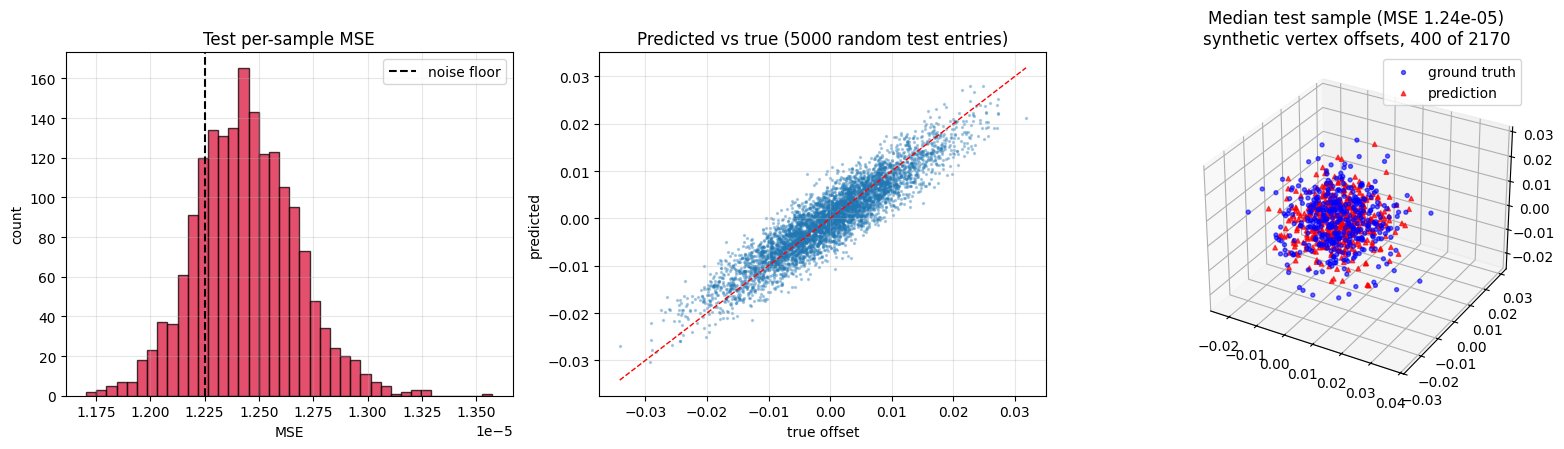

In [31]:
sel_model = models[(selected, best_seed)]   # best seed by validation MSE (see section 5b)
pred_te = predict(sel_model, Xte_t)
per_sample = ((pred_te - Yte_t) ** 2).mean(1).cpu().numpy()
med_idx = int(np.argsort(per_sample)[len(per_sample) // 2])
gt = Y_test[med_idx].reshape(N_VERTS, 3); pr = pred_te[med_idx].cpu().numpy().reshape(N_VERTS, 3)
plot_rng = np.random.default_rng(0)
sub = plot_rng.choice(N_VERTS, 400, replace=False)
ent = plot_rng.choice(Y_test.size, 5000, replace=False)

print(f"{selected}: test MSE {mse(pred_te, Yte_t):.3e} | mean vertex error {vertex_err(pred_te, Yte_t):.4f} "
      f"| per-sample MSE median {np.median(per_sample):.3e}, 95th pct {np.percentile(per_sample, 95):.3e}")

fig = plt.figure(figsize=(16, 4.6))
ax1 = fig.add_subplot(1, 3, 1)
ax1.hist(per_sample, bins=40, color="crimson", alpha=.75, edgecolor="k")
ax1.axvline(noise_floor, color="k", ls="--", label="noise floor"); ax1.legend()
ax1.set_title("Test per-sample MSE"); ax1.set_xlabel("MSE"); ax1.set_ylabel("count"); ax1.grid(True, alpha=.3)

ax2 = fig.add_subplot(1, 3, 2)
yt, yp = Y_test.ravel()[ent], pred_te.cpu().numpy().ravel()[ent]
ax2.scatter(yt, yp, s=2, alpha=.3); lim = [yt.min(), yt.max()]; ax2.plot(lim, lim, "r--", lw=1)
ax2.set_title("Predicted vs true (5000 random test entries)"); ax2.set_xlabel("true offset"); ax2.set_ylabel("predicted"); ax2.grid(True, alpha=.3)

ax3 = fig.add_subplot(1, 3, 3, projection="3d")
ax3.scatter(*gt[sub].T, c="blue", s=8, alpha=.6, label="ground truth")
ax3.scatter(*pr[sub].T, c="red", marker="^", s=10, alpha=.7, label="prediction")
ax3.set_title(f"Median test sample (MSE {per_sample[med_idx]:.2e})\nsynthetic vertex offsets, 400 of {N_VERTS}"); ax3.legend()
plt.tight_layout(); plt.show()

## 7. Inference latency

Measured for **this MLP on this hardware** only. It is deliberately *not* compared with a physics solver:
no solver was run here, and timings quoted in the paper come from different hardware and a real simulator.

In [32]:
def latency(model, batch, reps=200):
    x = Xte_t[:batch]; model.eval()
    sync = torch.cuda.synchronize if device.type == "cuda" else (lambda: None)
    with torch.no_grad():
        for _ in range(20): model(x)                    # warm-up
        times = []
        for _ in range(reps):
            sync(); t = time.perf_counter(); model(x); sync()
            times.append(time.perf_counter() - t)
    return np.median(times)

for b in (1, 100):
    s = latency(sel_model, b)
    print(f"{selected} | device={device} | batch {b:<3}: {s*1e3:.3f} ms per call = {s/b*1e6:.1f} us per pose")

64 PCA coeffs (64) | device=cuda | batch 1  : 0.238 ms per call = 237.9 us per pose
64 PCA coeffs (64) | device=cuda | batch 100: 0.362 ms per call = 3.6 us per pose


## 8. Standalone inference from the saved artifacts

`infer_cloth.py` (next to this notebook) loads `artifacts/` with **NumPy only** and predicts offsets for a new 56-D pose - no training data, no PyTorch, no retraining. The cell below (1) checks that it reproduces the in-memory model's predictions and (2) predicts for a brand-new random pose.

The same thing from a terminal:

```bash
python infer_cloth.py --random 3 --out pred.npy
python infer_cloth.py --pose my_pose.npy --out pred.npy     # (56,), (N,56), (14,4) or (N,14,4)
```

*Needs `infer_cloth.py` in the working directory (clone the repository, or upload the file in Colab).*

In [33]:
import importlib, infer_cloth
importlib.reload(infer_cloth)
from infer_cloth import ClothPredictor

predictor = ClothPredictor("artifacts")           # loads artifacts only; sel_model is NOT used below

# (1) round-trip check: loaded artifacts vs. the in-memory trained model on a few test poses
check_poses = X_test[:8]
ref = predict(sel_model, Xte_t[:8]).cpu().numpy()
got = predictor.predict(check_poses)
max_diff = float(np.abs(got.reshape(len(check_poses), -1) - ref).max())
print(f"max |loaded - in-memory| over 8 test poses: {max_diff:.2e}")
assert max_diff < 1e-5, "saved artifacts do not reproduce the trained model"

# (2) a brand-new pose (random unit quaternions) -> cloth offsets
new_q = np.random.default_rng(123).standard_normal((N_JOINTS, 4))
new_pose = (new_q / np.linalg.norm(new_q, axis=-1, keepdims=True)).reshape(-1)     # shape (56,)
offsets = predictor.predict(new_pose)                                               # shape (2170, 3)
print("new pose", new_pose.shape, "->", offsets.shape, "| mean |offset| =", f"{np.abs(offsets).mean():.4f}")
print("(synthetic data units; these are not real cloth offsets)")

max |loaded - in-memory| over 8 test poses: 1.77e-08
new pose (56,) -> (2170, 3) | mean |offset| = 0.0064
(synthetic data units; these are not real cloth offsets)


## Reading the results (final local run: DATA_SEED=42, MODEL_SEEDS=0,1,2)

All results below come from the completed local execution of this notebook on the synthetic generator.

- **Everything good sits at the noise floor.** Noise floor = **1.225e-05**; linear regression test MSE = **1.238e-05**; PCA-MLPs = **1.244e-05 to 1.253e-05**. The data is nearly linearly predictable, so linear regression is essentially tied with the best MLPs. This is a property of the synthetic generator, not evidence about real cloth.

- **PCA output layer helps the MLP substantially under the fixed training budget.** The direct 6,510-D MLP has test MSE **3.881e-05 ± 2.9e-06**, compared with about **1.24e-05** for the PCA-based MLPs. The direct model was still underfitting at the fixed learning rate and batch size and was not tuned further, so this comparison should be interpreted as a result under this training budget.

- **PCA-64 was selected.** PCA-64 has the lowest mean validation MSE among the tested MLP configurations. The differences between PCA-64, PCA-128 and PCA-256 are only about 1–2% of the error and are specific to this synthetic generator; they do not imply that 64 components is optimal for real cloth.

- **Train/validation/test discipline is maintained.** PCA is fitted on training targets only, validation MSE is used for early stopping and model selection, and the test set is used only for final reporting.

- **Deployment.** The selected configuration is **PCA-64, seed 0**. The saved artifacts reproduce the in-memory model within the notebook's verification tolerance and can be used by `infer_cloth.py` without retraining or PyTorch.

- **Latency.** Batch-size-1 PyTorch inference on the local development machine measured **0.238 ms per pose on CUDA**. This is a model-inference measurement only; no physics solver was run, so no speed-up over physics-based simulation is claimed.

### Notes and limitations

- **Synthetic data.** All results characterize the synthetic generator. They do not reproduce the Stanford paper's tables or figures and do not establish real cloth quality.
- **Injected outliers.** The 187 failed-simulation samples are synthetic outliers injected by this notebook so that the 10,000 → 9,813 filtering step is explicit and verifiable. They are not real solver failures.
- **Weak non-linearity.** The generator contains a dominant linear component with small non-linear terms, so Linear Regression reaches almost the same error as the MLPs.
- **PCA-size ranking.** The small advantage of PCA-64 is a generator-specific effect.
- **Direct-MLP comparison.** The direct-output model was not further hyperparameter-tuned, so the PCA-vs-direct gap should be interpreted under the fixed training budget used here.
- **Runtime.** The latency was measured on one machine and was not compared against a physics simulator.
- **Output interpretation.** The predicted values are synthetic vertex offsets in generator units, not metres or real cloth geometry.